# 🛡️ Итгэлцлийн оноо — скоркарт загвар v4 (шударга үнэлгээтэй)

**v3.1-ээс юу өөрчлөгдсөн бэ** (grill-ээр тохирсон шийдвэрүүд):

| # | Шийдвэр |
|---|---|
| 1 | **Нэг CSV** уншина. Хуучин `split` баганыг үл тоомсорлож, хуваалтыг зөвхөн энэ notebook хийнэ |
| 2 | **Цаг хугацаа + `pair_id` бүлгээр** хуваана: хамгийн шинэ мэдээ → test («ирээдүйн мэдээн дээр ажиллах уу?») |
| 3 | LLM-ээр дахин бичсэн мөр **зөвхөн train-д**. Эх мөр нь val/test-д байвал хасагдана |
| 4 | **70 / 15 / 15** |
| 5 | Facebook-ийн бодит постоор **holdout** (байвал) — хамгийн сүүлд, `trust_score()`-оор |
| 6 | Overfit-ийн 3 хэмжүүр: **train vs val зөрүү, 5-fold CV, learning curve** |
| 9 | CV ба out-of-fold оноо → **`StratifiedGroupKFold`** |
| 10 | Эцсийн загварыг **train+val** дээр сургана. `hackmil_scorecard.joblib`-ийн бүтэц хэвээр |

**Дүрэм:** загвар сонголт зөвхөн val / CV дээр. Test-ийг **10-р алхамд ганц удаа** ажиллуулна.

In [1]:
# !pip install -q lightgbm scikit-learn pandas matplotlib joblib openpyxl
import re, joblib, numpy as np, pandas as pd, lightgbm as lgb, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, StratifiedGroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, classification_report, cohen_kappa_score

DATA    = "../../data/datasets/HACKMIL_dataset_v31.csv"     # ← НЭГ CSV (бүх мөр)
HOLDOUT = "../../data/datasets/HACKMIL_holdout.csv"         # ← Facebook-ийн бодит пост (.csv эсвэл .xlsx). Байхгүй бол алгасна
RATIOS  = {"train": 0.70, "val": 0.15, "test": 0.15}
SEED    = 42

## 0. Өгөгдөл унших
`HACKMIL_dataset_v31.csv` байхгүй, харин хуучин `_train/_val/_test` гурван файл байвал **нэг удаа** нийлүүлж хадгална.

In [4]:
# Нэг CSV байхгүй бол хуучин 3 файлыг нийлүүлнэ (нэг л удаа)
parts = [DATA.replace(".csv", f"_{s}.csv") for s in ("train", "val", "test")]
if not Path(DATA).exists() and all(Path(p).exists() for p in parts):
    pd.concat([pd.read_csv(p) for p in parts], ignore_index=True).to_csv(DATA, index=False, encoding="utf-8-sig")
    print(f"🔗 3 файлыг нийлүүлж {DATA} үүсгэлээ")

df = pd.read_csv(DATA)
df = df.drop(columns=["split"], errors="ignore")           # хуучин хуваалтыг үл тоомсорлоно
df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(int)
# pair_id хоосон бол мөр бүр өөрийн бүлэг
df["pair_id"] = df["pair_id"].astype(str).where(df["pair_id"].notna(), "row" + df.index.astype(str))
# Хүний бичсэн эсэх: is_llm = none/хоосон → хүн
df["is_human"] = df.get("is_llm", pd.Series("none", index=df.index)).fillna("none").astype(str) \
                   .str.strip().str.lower().isin(["none", "", "nan", "0", "false"])
df["date_"] = pd.to_datetime(df.get("date"), errors="coerce")
print(f"Нийт {len(df)} мөр | хүн {df.is_human.sum()} | LLM {(~df.is_human).sum()}")
print(pd.crosstab(df.is_human.map({True: "хүн", False: "LLM"}), df.label.map({0: "үнэн", 1: "худал"})))

Нийт 3107 мөр | хүн 2869 | LLM 238
label     худал  үнэн
is_human             
LLM         105   133
хүн        1982   887


## 1. Хуваалт: цаг хугацаа + бүлэг, 70/15/15
Ангилал бүрт тусад нь: бүлгүүдийг **хамгийн сүүлийн огноогоор** эрэмбэлээд хамгийн шинэ 15% → test, дараагийн 15% → val.
Ингэснээр үнэн/худлын харьцаа хэсэг бүрт ижил (stratified) байна.
Нэг бүлэгт хоёр шошго байвал бүлгийг бүхэлд нь test > val > train дарааллаар нэг хэсэгт оруулна.

In [5]:
PRIO = {"test": 0, "val": 1, "train": 2}

def time_group_split(d, ratios=RATIOS):
    d = d.copy()
    d["split"] = "train"
    H = d[d.is_human]
    for lab in (0, 1):
        part = H[H.label == lab]
        order = part.groupby("pair_id")["date_"].max().sort_values(ascending=False, na_position="last", kind="stable")
        sizes = part.groupby("pair_id").size()
        n_test, n_val = round(len(part) * ratios["test"]), round(len(part) * ratios["val"])
        assign, acc = {}, 0
        for g in order.index:                       # хамгийн шинэ бүлгээс эхэлнэ
            assign[g] = "test" if acc < n_test else ("val" if acc < n_test + n_val else "train")
            acc += sizes[g]
        idx = part.index
        d.loc[idx, "split"] = d.loc[idx, "pair_id"].map(assign)
    # Хоёр шошготой бүлэг хоёр хэсэгт тарсан бол → нэг хэсэгт
    hum = d.is_human
    best = d[hum].groupby("pair_id")["split"].agg(lambda s: min(s, key=PRIO.get))
    d.loc[hum, "split"] = d.loc[hum, "pair_id"].map(best)
    # LLM мөр эх бүлгээ дагана. Эх нь val/test-д бол хасна. Эх мөргүй бол train
    llm = ~d.is_human
    d.loc[llm, "split"] = d.loc[llm, "pair_id"].map(best).fillna("train")
    dropped = d[llm & (d.split != "train")]
    return d[~(llm & (d.split != "train"))].reset_index(drop=True), dropped

df, llm_dropped = time_group_split(df)
print(f"LLM мөрөөс хасагдсан (эх нь val/test-д): {len(llm_dropped)}\n")
print(pd.crosstab(df.split, df.label.map({0: "үнэн", 1: "худал"}), margins=True, margins_name="нийт"))
print("\nОгнооны хүрээ (хүний мөр):")
print(df[df.is_human].groupby("split")["date_"].agg(["min", "max"]))

LLM мөрөөс хасагдсан (эх нь val/test-д): 34

label  худал  үнэн  нийт
split                   
test     297   133   430
train   1472   737  2209
val      297   137   434
нийт    2066  1007  3073

Огнооны хүрээ (хүний мөр):
             min        max
split                      
test  2025-08-28 2026-10-25
train 2020-01-20 2026-10-21
val   2021-08-03 2026-10-22


### Leakage шалгалт — бүгд **0** байх ёстой

In [6]:
def leakage_report(d):
    out = {
        "хэд хэдэн хэсэгт тарсан pair_id": int((d.groupby("pair_id")["split"].nunique() > 1).sum()),
        "val/test дэх LLM мөр": int(((~d.is_human) & (d.split != "train")).sum()),
    }
    # Бараг ижил текст (cosine ≥ 0.9) train ба val/test хооронд
    X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit_transform(d.text)
    tr, ev = (d.split == "train").to_numpy(), (d.split != "train").to_numpy()
    best = (X[ev] @ X[tr].T).max(axis=1).toarray().ravel()
    out["val/test мөр, train-д cos≥0.9 хостой"] = int((best >= 0.9).sum())
    return out

for k, v in leakage_report(df).items():
    print(f"{'✅' if v == 0 else '⚠️'} {k}: {v}")

train = df[df.split == "train"].reset_index(drop=True)
val   = df[df.split == "val"].reset_index(drop=True)
test  = df[df.split == "test"].reset_index(drop=True)

✅ хэд хэдэн хэсэгт тарсан pair_id: 0
✅ val/test дэх LLM мөр: 0
✅ val/test мөр, train-д cos≥0.9 хостой: 0


## 2. Шинж тэмдгүүд (скоркартын «Текст» бүлэг)
`+1` = эрсдэл нэмнэ (итгэлцэл бууруулна), `-1` = итгэлцэл нэмнэ, `0` = чиглэл тогтоохгүй. v3.1-тэй ижил.

In [7]:
SIGNALS = {  # нэр: (regex, чиглэл, reason, MIL карт)
    "clickbait":     (r"шок\b|итгэхгүй|гайхмаар|хараарай|үзээрэй|нууц нь|цочирдм", +1, "Clickbait хэллэг", "Clickbait гарчиг яагаад аюултай вэ?"),
    "emotion":       (r"аймшиг|айхтар|гамшиг|үхэл|үхүүл|аюул|харамсалтай|эмгэнэл|эмзэглүүл|сүйрэл|айдас", +1, "Айдас, сэтгэл хөдлөл өдөөсөн үг", "Сэтгэл хөдлөл шүүлтийг яаж халхалдаг вэ?"),
    "urgency":       (r"яаралтай|шэйр|шейр|хуваалцаарай|тараа(рай|гаарай)|амжаарай|устгагдах", +1, "Яаруулж, тараахыг шаардсан", "«Яаралтай шэйрлээрэй» гэвэл яагаад зогсох вэ?"),
    "absolute":      (r"100\s?%|бүрэн эдгэр|хэзээ ч|ганцхан|гайхамшиг|шидэт|баталгаатай", +1, "Хэтрүүлсэн, туйлширсан амлалт", "«100% эдгэрнэ» гэдэгт яагаад эргэлзэх вэ?"),
    "conspiracy":    (r"нууж|нуудаг|нууцал|биднээс|хуйвалд|далд|сэрээрэй", +1, "Хуйвалдааны хэллэг", "«Тэд нууж байна» хэллэгийг таних"),
    "anon_source":   (r"эрдэмтэд|судлаачид|эмч нар|гэнэ\b|гэнээ|гэсэн байна|эх сурвалжийн мэдээлснээр|сонссон", +1, "Нэргүй эсвэл тодорхойгүй эх сурвалж", "Яагаад нэргүй эх сурвалжаас болгоомжлох вэ?"),
    "scam":          (r"линк|дарж|хожсон|хонжвор|бэлэг|данс|картын|урамшуулал|үнэгүй ав|дугаараа", +1, "Луйврын урхины шинж", "Цахим луйврыг яаж таних вэ?"),
    "call_to_action":(r"(аарай|ээрэй|оорой|өөрэй)\b", +1, "Үйлдэл хийхийг шаардсан", "Яагаад «хуваалц», «дар» гэж шахдаг вэ?"),
    "named_source":  (r"яам|газар|хороо|агентлаг|хүрээлэн|мэдээлснээр|мэдэгдэв|мэдээллээ|тогтоол|засгийн газ|уих|их хурал|шүүх|цагдаа", -1, "Нэр бүхий байгууллагад эш татсан", "Эх сурвалжийг яаж шалгах вэ?"),
}
EXTRA = {  # тоон шинжүүд: (чиглэл, reason, илэрсэн гэж тооцох босго)
    "caps":         (+1, "Том үсэг хэт олон", 0.30),
    "exclaim":      (+1, "Анхаарлын тэмдэг хэт олон", 2),
    "question":     (+1, "Риторик асуулт", 2),
    "emoji":        (+1, "Emoji хэт олон", 2),
    "named_person": (-1, "Нэр бүхий хүнд эш татсан", 1),
    "numbers":      (0, None, None),
    "n_words":      (0, None, None),
}
EMOJI = re.compile("[\U0001F300-\U0001FAFF☀-➿]")
INITIALS = re.compile(r"\b[А-ЯЁӨҮ]\.[А-ЯЁӨҮ][а-яёөү]+")      # «Н.Учрал» гэх мэт

def signals(texts):
    rows = []
    for t in texts:
        t = str(t); low = t.lower(); n = max(len(t), 1)
        r = {k: len(re.findall(v[0], low)) for k, v in SIGNALS.items()}
        r.update(caps=sum(c.isupper() for c in t) / n, exclaim=t.count("!"), question=t.count("?"),
                 emoji=len(EMOJI.findall(t)), named_person=len(INITIALS.findall(t)),
                 numbers=len(re.findall(r"\d", t)) / n, n_words=len(t.split()))
        rows.append(r)
    return pd.DataFrame(rows)

print("Шинж бүрийн дундаж (0 = үнэн, 1 = худал), train:")
signals(train.text).assign(label=train.label).groupby("label").mean().T.round(3)

Шинж бүрийн дундаж (0 = үнэн, 1 = худал), train:


label,0,1
clickbait,0.001,0.004
emotion,0.035,0.039
urgency,0.001,0.019
absolute,0.001,0.013
conspiracy,0.043,0.021
anon_source,0.031,0.073
scam,0.011,0.052
call_to_action,0.034,0.068
named_source,0.539,0.097
caps,0.035,0.052


## 3. Загварын «жор» — нэг функцээр
`fit_full(өгөгдөл)` нь бүх сургалтыг нэг дор хийнэ. Ингэснээр CV, learning curve, сайт нуух туршилт, эцсийн загвар **яг ижил аргаар** сурна.

1. TF-IDF+LR текст ангилагчийн оноог **out-of-fold** (`StratifiedGroupKFold`) аргаар тооцно — LightGBM цээжилсэн оноо харахгүй
2. LightGBM + monotonic constraint
3. Isotonic калибровк — калибровкийн fold-ууд ч `pair_id`-аар бүлэглэгдэнэ (leakage-гүй)

LLM мөрийг зөвхөн сургалтын хэсэгт нэмдэг `with_llm()` туслах функц бий.

In [8]:
MONO = {**{k: v[1] for k, v in SIGNALS.items()}, **{k: v[0] for k, v in EXTRA.items()}, "text_model": +1}
SIG_COLS = list(SIGNALS) + list(EXTRA)
COLS = SIG_COLS + ["text_model"]

def text_model():
    return Pipeline([("tf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=200000)),
                     ("lr", LogisticRegression(max_iter=3000, class_weight="balanced", C=2.0))])

def lgbm(cols=COLS):
    return lgb.LGBMClassifier(objective="binary", learning_rate=0.05, num_leaves=15, min_child_samples=20,
                              n_estimators=400, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              monotone_constraints=[MONO[c] for c in cols], is_unbalance=True, verbose=-1, random_state=SEED)

def sgkf(k):
    return StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEED)

def fit_full(d, inner=5, cols=COLS):
    """d дээр бүх загварыг сургана. Буцаах: {"tm", "model", "explainer", "cols"}"""
    d = d.reset_index(drop=True)
    S = signals(d.text)
    S["text_model"] = cross_val_predict(text_model(), d.text, d.label, cv=sgkf(inner), groups=d.pair_id,
                                        method="predict_proba")[:, 1]          # out-of-fold
    tm = text_model().fit(d.text, d.label)
    cal_cv = list(sgkf(5).split(S, d.label, d.pair_id))                        # калибровк ч бүлгээр
    model = CalibratedClassifierCV(lgbm(cols), method="isotonic", cv=cal_cv).fit(S[cols], d.label)
    explainer = lgbm(cols).fit(S[cols], d.label)                               # SHAP тайлбарт (калибровкгүй)
    return {"tm": tm, "model": model, "explainer": explainer, "cols": cols}

def predict(b, texts):
    """Худал байх магадлал + шинжүүд"""
    S = signals(texts); S["text_model"] = b["tm"].predict_proba(list(texts))[:, 1]
    return b["model"].predict_proba(S[b["cols"]])[:, 1], S

LLM_POOL = df[~df.is_human]                     # бүх LLM мөр (бүгд train-д)
def with_llm(human_part):
    """Хүний мөрүүд + эх нь энэ хэсэгт байгаа LLM мөрүүд (зөвхөн сургалтад)"""
    return pd.concat([human_part, LLM_POOL[LLM_POOL.pair_id.isin(human_part.pair_id)]], ignore_index=True)

def metrics(y, p):
    y = np.asarray(y); trust = 100 * (1 - p)
    return {"acc": accuracy_score(y, p >= .5), "macroF1": f1_score(y, p >= .5, average="macro"),
            "AUC": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
            "үнэн→🔴": ((trust < 40) & (y == 0)).sum() / max((y == 0).sum(), 1),     # бодит мэдээ улаан бүсэд
            "худал→🟢": ((trust >= 70) & (y == 1)).sum() / max((y == 1).sum(), 1)}   # худал мэдээ ногоон бүсэд

def show(name, m):
    print(f"{name:34s} acc={m['acc']:.3f}  macroF1={m['macroF1']:.3f}  AUC={m['AUC']:.3f}  "
          f"үнэн→🔴 {m['үнэн→🔴']:5.1%}  худал→🟢 {m['худал→🟢']:5.1%}")

def zone(trust):
    return "🟢 ногоон" if trust >= 70 else ("🟡 шар" if trust >= 40 else "🔴 улаан")
print("OK")

OK


## 4. Аль хувилбар вэ? (зөвхөн **val** дээр)
Зөвхөн шинж тэмдэг / зөвхөн текст ангилагч / хоёулаа.

In [9]:
for name, cols in [("Зөвхөн шинж тэмдэг", SIG_COLS), ("Зөвхөн текст ангилагч", ["text_model"]), ("Шинж тэмдэг + текст", COLS)]:
    b = fit_full(train, cols=cols)
    show(name + " (val)", metrics(val.label, predict(b, val.text)[0]))

Зөвхөн шинж тэмдэг (val)           acc=0.779  macroF1=0.741  AUC=0.817  үнэн→🔴 24.8%  худал→🟢  2.7%
Зөвхөн текст ангилагч (val)        acc=0.931  macroF1=0.921  AUC=0.977  үнэн→🔴  6.6%  худал→🟢  1.7%
Шинж тэмдэг + текст (val)          acc=0.929  macroF1=0.917  AUC=0.973  үнэн→🔴 10.2%  худал→🟢  3.4%


## 5. Хөгжүүлэлтийн загвар (зөвхөн train) ба **train vs val зөрүү**
Шалгалтын асуултыг цээжилсэн сурагч өөрийн дасгал дээр 100 авч, шинэ асуулт дээр унадаг. Тэгэхээр **хоёулангийн зөрүүг** харна.

- Char TF-IDF загвар train-ийг бараг цээжилдэг тул train-ийн оноо 97–100% байх нь **хэвийн**.
- Чухал нь: **val-ийн оноо өндөр** бөгөөд **CV-ийн fold-уудын хооронд тогтвортой** байх (6-р алхам).

In [24]:
DEV = fit_full(train)                           # хөгжүүлэлтийн загвар — test, хэцүү тестэд ашиглана
m_tr = metrics(train.label, predict(DEV, train.text)[0])
m_va = metrics(val.label, predict(DEV, val.text)[0])
show("Train (загвар харсан)", m_tr)
show("Val (загвар хараагүй)", m_va)
gap = m_tr["acc"] - m_va["acc"]
# TF-IDF train-ийг цээжилдэг тул бага зэргийн зөрүү хэвийн. Гол нь val өндөр, CV тогтвортой байх
print(f"\nЗөрүү: {gap:+.1%}  →  " + ("✅ хэвийн" if gap < 0.08 else "🟡 ажиглах" if gap < 0.15 else "⚠️ overfit-ийн шинж"))

Train (загвар харсан)              acc=0.984  macroF1=0.982  AUC=0.997  үнэн→🔴  2.0%  худал→🟢  0.7%
Val (загвар хараагүй)              acc=0.929  macroF1=0.917  AUC=0.973  үнэн→🔴 10.2%  худал→🟢  3.4%

Зөрүү: +5.6%  →  ✅ хэвийн


## 6. 5-fold CV (`StratifiedGroupKFold`, train+val дээр)
Ганц val нь «азтай/азгүй» гарч болно. 5 өөр хуваалтын **дундаж ± хазайлт** илүү найдвартай.
LLM мөр зөвхөн сургалтын fold-д орно. *(Хэдэн минут ажиллана.)*

In [25]:
dev_h = pd.concat([train, val])
dev_h = dev_h[dev_h.is_human].reset_index(drop=True)
rows = []
for f, (tr_i, va_i) in enumerate(sgkf(5).split(dev_h, dev_h.label, dev_h.pair_id), 1):
    tr_d, va_d = dev_h.iloc[tr_i], dev_h.iloc[va_i]
    b = fit_full(with_llm(tr_d), inner=3)
    r = metrics(va_d.label, predict(b, va_d.text)[0])
    r["train_acc"] = accuracy_score(tr_d.label, predict(b, tr_d.text)[0] >= .5)
    rows.append({"fold": f, **r})
    print(f"fold {f}: val acc={r['acc']:.3f}  train acc={r['train_acc']:.3f}")
CV = pd.DataFrame(rows).set_index("fold")
print("\nДундаж ± хазайлт:")
print(CV.agg(["mean", "std"]).T.round(3))

fold 1: val acc=0.924  train acc=0.984
fold 2: val acc=0.906  train acc=0.987
fold 3: val acc=0.932  train acc=0.982
fold 4: val acc=0.926  train acc=0.989
fold 5: val acc=0.897  train acc=0.991

Дундаж ± хазайлт:
            mean    std
acc        0.917  0.015
macroF1    0.903  0.016
AUC        0.950  0.009
үнэн→🔴     0.134  0.023
худал→🟢    0.033  0.015
train_acc  0.986  0.004


## 7. Learning curve
«Өгөгдөл нэмбэл сайжрах уу?» — val-ийн шугам дээшээ явсаар байвал **дата нэмэх нь үр дүнтэй**.
Хоёр шугам ойртож, хавтгай болсон бол загвар дээд хэмжээндээ хүрсэн.

    мөр  train    val
0   401  0.993  0.859
1   804  0.984  0.901
2  1202  0.985  0.926
3  1607  0.983  0.912
4  2005  0.983  0.931


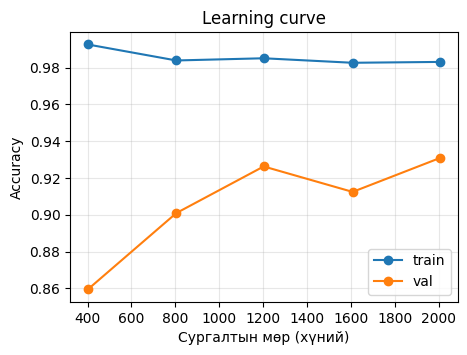

In [26]:
tr_h = train[train.is_human]
groups = tr_h.pair_id.drop_duplicates().sample(frac=1, random_state=SEED).tolist()
LC = []
for frac in (0.2, 0.4, 0.6, 0.8, 1.0):
    part = tr_h[tr_h.pair_id.isin(groups[: max(2, int(len(groups) * frac))])]
    b = fit_full(with_llm(part), inner=3)
    LC.append({"мөр": len(part), "train": accuracy_score(part.label, predict(b, part.text)[0] >= .5),
               "val": accuracy_score(val.label, predict(b, val.text)[0] >= .5)})
LC = pd.DataFrame(LC); print(LC.round(3))
plt.figure(figsize=(5, 3.5)); plt.plot(LC["мөр"], LC.train, "o-", label="train"); plt.plot(LC["мөр"], LC.val, "o-", label="val")
plt.xlabel("Сургалтын мөр (хүний)"); plt.ylabel("Accuracy"); plt.title("Learning curve"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 8. Хэцүү тест (хэв маягаар хуурагдах эсэх)
Энгийн test ба хэцүү тестийн **зөрүү** = загвар хэв маягт хэр найдаж байгаа. Хөгжүүлэлтийн загвар (DEV) ашиглана.

In [13]:
PROBES = [  # (бүлэг, зөв хариу 0=үнэн 1=худал, текст) — багаараа нэмээрэй
    ("A үнэн+ярианы", 0, "Маргаашнаас гэр хорооллынхны цахилгааны шөнийн тариф хямдарна шүү, мэдээрэй!"),
    ("A үнэн+ярианы", 0, "Хүүхдээ эрт илрүүлгийн үзлэгт хамруулаарай, сургууль цэцэрлэг дээр нь үнэгүй хийж байгаа юм билээ"),
    ("A үнэн+ярианы", 0, "Сурагчид ирэх долоо хоногт хичээллээд дараа нь амарна гэнэ ээ"),
    ("A үнэн+ярианы", 0, "Зуны дугуйтай явж болохгүй шүү, зам их халтиргаатай байна. Өвлийн дугуйгаа сольцгоо"),
    ("A үнэн+ярианы", 0, "Налайх орчимд баавгай үзэгдсэн гэнэ, гадуур явахдаа болгоомжтой байгаарай"),
    ("B худал+албан", 1, "Эрүүл мэндийн яамнаас мэдээлснээр сод уусгасан ус өдөр бүр уухад хорт хавдар бүрэн эдгэрдэг болох нь тогтоогджээ"),
    ("B худал+албан", 1, "Засгийн газрын хуралдаанаар 2027 оноос эхлэн иргэн бүрийн хадгаламжийн 30 хувийг төрд шилжүүлэх шийдвэр гаргалаа"),
    ("B худал+албан", 1, "Монголбанкны ерөнхийлөгч ирэх сарын 1-нээс төгрөгийн бүх дэвсгэртийг хүчингүй болгохыг мэдэгдэв"),
    ("B худал+албан", 1, "УИХ-ын чуулганы хуралдаанаар Монгол Улс цөмийн хог хаягдал хүлээн авах гэрээг соёрхон баталлаа"),
    ("B худал+албан", 1, "ДЭМБ-аас гаргасан судалгаагаар ковидын вакцин хийлгэсэн хүмүүсийн 40 хувь нь үргүйдсэн байна"),
    ("C худал+манипуляц", 1, "ЯАРАЛТАЙ!!! Эмч нар нууж байгаа энэ аргаар 3 хоногт чихрийн шижин 100% эдгэрнэ, ШЭЙРЛЭЭРЭЙ"),
    ("C худал+манипуляц", 1, "Банкнаас 500,000 төгрөгийн бэлэг хожсон байна, линк дээр дарж картын дугаараа баталгаажуулаарай"),
    ("C худал+манипуляц", 1, "Тэд биднээс нууж байна. Вакцин дотор чип суулгаад бүгдийг хянаж байгаа, сэрээрэй монголчууд аа"),
    ("D үнэн+албан", 0, "УИХ-ын намрын ээлжит чуулганы хуралдаанаар 2027 оны төсвийн төслийг хэлэлцэх эсэхийг шийдвэрлэлээ"),
    ("D үнэн+албан", 0, "Нийслэлийн Засаг дарга иргэдийн газар өмчлөх ажлыг эрчимжүүлэх үүрэг даалгавар өглөө"),
    ("D үнэн+албан", 0, "Ой, хээрийн түймрийн тохиолдол өмнөх оны мөн үетэй харьцуулахад 29 хувиар буурсан байна"),
]
pr = pd.DataFrame(PROBES, columns=["бүлэг", "зөв", "текст"])
pr["итгэлцэл"] = (100 * (1 - predict(DEV, pr["текст"])[0])).round()
pr["бүс"] = pr["итгэлцэл"].map(zone)
pr["зөв таасан"] = np.where(pr["зөв"] == 0, pr["итгэлцэл"] >= 40, pr["итгэлцэл"] < 70)   # үнэн → 🔴 биш, худал → 🟢 биш
print(pr.groupby("бүлэг")["зөв таасан"].agg(["sum", "count"]))
print(f"\nХэцүү тест: {pr['зөв таасан'].mean():.0%}  (16 жишээ — 1 жишээ = 6 пункт)")
pr[["бүлэг", "итгэлцэл", "бүс", "текст"]]

                   sum  count
бүлэг                        
A үнэн+ярианы        0      5
B худал+албан        3      5
C худал+манипуляц    3      3
D үнэн+албан         3      3

Хэцүү тест: 56%  (16 жишээ — 1 жишээ = 6 пункт)


,бүлэг,итгэлцэл,бүс,текст
0,A үнэн+ярианы,10.0,🔴 улаан,Маргаашнаас гэр хорооллынхны цахилгааны шөнийн...
1,A үнэн+ярианы,30.0,🔴 улаан,"Хүүхдээ эрт илрүүлгийн үзлэгт хамруулаарай, су..."
2,A үнэн+ярианы,5.0,🔴 улаан,Сурагчид ирэх долоо хоногт хичээллээд дараа нь...
3,A үнэн+ярианы,28.0,🔴 улаан,"Зуны дугуйтай явж болохгүй шүү, зам их халтирг..."
4,A үнэн+ярианы,7.0,🔴 улаан,"Налайх орчимд баавгай үзэгдсэн гэнэ, гадуур яв..."
5,B худал+албан,20.0,🔴 улаан,Эрүүл мэндийн яамнаас мэдээлснээр сод уусгасан...
6,B худал+албан,94.0,🟢 ногоон,Засгийн газрын хуралдаанаар 2027 оноос эхлэн и...
7,B худал+албан,37.0,🔴 улаан,Монголбанкны ерөнхийлөгч ирэх сарын 1-нээс төг...
8,B худал+албан,93.0,🟢 ногоон,УИХ-ын чуулганы хуралдаанаар Монгол Улс цөмийн...
9,B худал+албан,4.0,🔴 улаан,ДЭМБ-аас гаргасан судалгаагаар ковидын вакцин ...


## 9. Сайтыг бүхэлд нь нууж шалгах
Нэг мэдээний сайтыг сургалтаас **бүрэн** хасаад, тэр сайтын мэдээний хэдэн хувь нь улаан бүсэд орж байгааг харна.

In [14]:
for site in (["ikon", "gogo", "eagle"] if "platform" in df.columns else []):
    held = df[df.is_human & (df.platform == site)]
    if held.empty:
        print(f"{site:6s}: мөр алга"); continue
    tr_h = train[train.is_human & (train.platform != site)]
    b = fit_full(with_llm(tr_h), inner=3)
    trust = 100 * (1 - predict(b, held.text)[0])
    print(f"{site:6s}: {len(held):3d} мэдээ (сургалтад ороогүй) → 🔴 {(trust < 40).mean():5.1%}  "
          f"🟡 {((trust >= 40) & (trust < 70)).mean():5.1%}  🟢 {(trust >= 70).mean():5.1%}")

ikon  : 277 мэдээ (сургалтад ороогүй) → 🔴 14.8%  🟡 10.1%  🟢 75.1%
gogo  : 273 мэдээ (сургалтад ороогүй) → 🔴 10.3%  🟡 13.9%  🟢 75.8%
eagle : 285 мэдээ (сургалтад ороогүй) → 🔴 10.2%  🟡 11.6%  🟢 78.2%


## 10. ⚠️ TEST — ганц удаа
Дээрх алхмуудаар бүх шийдвэрээ гаргасны **дараа** л ажиллуулна. Энд гарсан тоогоор загвараа дахин өөрчилбөл test «бохирдоно».
Хамгийн чухал тоо: **үнэн→🔴** (бодит мэдээг улаан бүсэд оруулсан хувь).

TEST                               acc=0.937  macroF1=0.928  AUC=0.974  үнэн→🔴  7.5%  худал→🟢  2.7%
              precision    recall  f1-score   support

        үнэн      0.879     0.925     0.901       133
       худал      0.966     0.943     0.954       297

    accuracy                          0.937       430
   macro avg      0.922     0.934     0.928       430
weighted avg      0.939     0.937     0.938       430

бүс    🔴 улаан  🟡 шар  🟢 ногоон
label                          
худал      271     18         8
үнэн        10     10       113


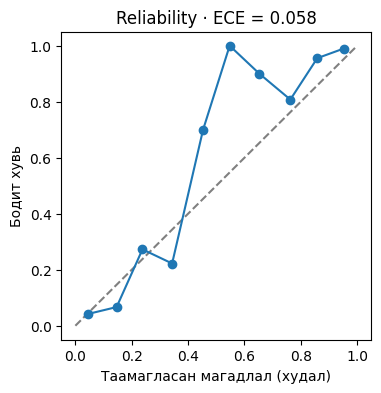

In [15]:
p_test = predict(DEV, test.text)[0]
show("TEST", metrics(test.label, p_test))
print(classification_report(test.label, p_test >= .5, target_names=["үнэн", "худал"], digits=3))
t = test.assign(trust=100 * (1 - p_test)); t["бүс"] = t.trust.map(zone)
print(pd.crosstab(t.label.map({0: "үнэн", 1: "худал"}), t["бүс"]))

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1); e, xs, ys = 0, [], []
    for k in range(bins):
        m = idx == k
        if m.any():
            e += m.mean() * abs(p[m].mean() - y[m].mean()); xs.append(p[m].mean()); ys.append(y[m].mean())
    return e, xs, ys

e, xs, ys = ece(test.label.values, p_test)
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", c="gray"); plt.plot(xs, ys, "o-")
plt.xlabel("Таамагласан магадлал (худал)"); plt.ylabel("Бодит хувь"); plt.title(f"Reliability · ECE = {e:.3f}"); plt.show()

## 11. Эцсийн загвар: **train + val** дээр
Үнэлгээ дууссан тул val-ийг ч сургалтад нэмнэ (илүү их өгөгдөл). Test-д огт хүрэхгүй.

In [16]:
FINAL = fit_full(pd.concat([train, val], ignore_index=True))
tm, model, explainer = FINAL["tm"], FINAL["model"], FINAL["explainer"]
print(f"Эцсийн загвар {len(train) + len(val)} мөр дээр сурлаа")

Эцсийн загвар 2643 мөр дээр сурлаа


## 12. SHAP шалтгаан ба `trust_score()` (текст + домэйн)
Домэйн модуль нь **шинжээчийн жин**тэй дүрэм — өгөгдлөөр сургаагүй.
*Анхаар:* backend-ийн guardrail (нотолгоогүй бол ногоон/улаан болгохгүй) энд **ороогүй** — энэ нь зөвхөн загварын оноо.

In [17]:
def reasons(S_row, b=None):
    b = b or FINAL; cols = b["cols"]
    contrib = b["explainer"].booster_.predict(S_row[cols], pred_contrib=True)[0][:-1]   # сүүлийнх = bias
    minus, plus = [], []
    for i in np.argsort(-np.abs(contrib)):
        f, c, v = cols[i], contrib[i], S_row[cols[i]].iloc[0]
        if f in SIGNALS:
            fired, text = v > 0, SIGNALS[f][2]
        elif f in EXTRA and EXTRA[f][1]:
            fired, text = v >= EXTRA[f][2], EXTRA[f][1]
        elif f == "text_model":
            fired, text = True, ("Бичлэгийн хэв маяг няцаагдсан мэдээтэй төстэй" if c > 0 else "Бичлэгийн хэв маяг мэдээллийн сайттай төстэй")
        else:
            continue
        if not fired:
            continue
        # Шинжээчийн тогтоосон чиглэлтэй зөрчилдөх шалтгааныг харуулахгүй
        if c > 0 and MONO[f] >= 0:
            minus.append(text)
        elif c < 0 and MONO[f] <= 0:
            plus.append(text)
        elif f == "text_model":
            (minus if c > 0 else plus).append(text)
    return minus[:3], plus[:2]

WHITELIST = ["ikon.mn", "gogo.mn", "eagle.mn", "news.mn", "montsame.mn", "unuudur.mn", "isee.mn", "bolod.mn", "24tsag.mn"]

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def domain_adjust(url):
    # Шинжээчийн жин: цагаан жагсаалт +10, дуурайсан нэр −30, HTTPS байхгүй −10
    if not url or not isinstance(url, str):
        return 0, []
    host = re.sub(r"^https?://(www\.)?", "", url.lower()).split("/")[0]
    if host in WHITELIST:
        return +10, ["+ Бүртгэлтэй хэвлэл мэдээллийн байгууллага"]
    adj, why = 0, []
    if any(0 < levenshtein(host, w) <= 2 for w in WHITELIST):
        adj -= 30; why.append("− Алдартай мэдээллийн сайтыг дуурайсан домэйн нэр")
    if url.lower().startswith("http://"):
        adj -= 10; why.append("− HTTPS байхгүй")
    return adj, why

def trust_score(text, url=None, b=None):
    b = b or FINAL
    p, S = predict(b, [text])
    d_adj, d_why = domain_adjust(url)
    trust = float(np.clip(100 * (1 - p[0]) + d_adj, 0, 100))
    minus, plus = reasons(S, b)
    return {"итгэлцэл": round(trust), "бүс": zone(trust),
            "эрсдэлийн шалтгаан": minus + [w for w in d_why if w.startswith("−")],
            "итгэлцлийн дохио": plus + [w for w in d_why if w.startswith("+")]}

for txt, url in [("ЯАРАЛТАЙ!!! Эмч нар нууж байгаа энэ аргаар 100% эдгэрнэ, шэйрлээрэй", None),
                 ("УИХ-ын чуулганы хуралдаанаар 2027 оны төсвийн төслийг хэлэлцэв", "https://ikon.mn/n/3r93"),
                 ("Банкнаас бэлэг хожсон байна, линк дээр дарж аваарай", "http://ik0n.mn/promo")]:
    print(trust_score(txt, url), "\n   ←", txt[:60], "\n")

{'итгэлцэл': 0, 'бүс': '🔴 улаан', 'эрсдэлийн шалтгаан': ['Бичлэгийн хэв маяг няцаагдсан мэдээтэй төстэй', 'Анхаарлын тэмдэг хэт олон', 'Нэргүй эсвэл тодорхойгүй эх сурвалж'], 'итгэлцлийн дохио': []} 
   ← ЯАРАЛТАЙ!!! Эмч нар нууж байгаа энэ аргаар 100% эдгэрнэ, шэй 

{'итгэлцэл': 100, 'бүс': '🟢 ногоон', 'эрсдэлийн шалтгаан': [], 'итгэлцлийн дохио': ['Бичлэгийн хэв маяг мэдээллийн сайттай төстэй', 'Нэр бүхий байгууллагад эш татсан', '+ Бүртгэлтэй хэвлэл мэдээллийн байгууллага']} 
   ← УИХ-ын чуулганы хуралдаанаар 2027 оны төсвийн төслийг хэлэлц 

{'итгэлцэл': 0, 'бүс': '🔴 улаан', 'эрсдэлийн шалтгаан': ['Бичлэгийн хэв маяг няцаагдсан мэдээтэй төстэй', 'Луйврын урхины шинж', 'Үйлдэл хийхийг шаардсан', '− Алдартай мэдээллийн сайтыг дуурайсан домэйн нэр', '− HTTPS байхгүй'], 'итгэлцлийн дохио': []} 
   ← Банкнаас бэлэг хожсон байна, линк дээр дарж аваарай 



## 13. 🧪 Holdout — Facebook-ийн бодит пост (байвал)
Энэ өгөгдөл **ямар ч шийдвэрт оролцоогүй** тул хамгийн шударга тоо. Эцсийн загварын `trust_score()`-оор үнэлнэ.

- `labeler_1`, `labeler_2` хоёулаа бөглөгдсөн бол **Cohen's κ** тооцож, санал зөрсөн мөрийг хасна
- Dataset-тэй ойролцоо (cos ≥ 0.6) мөрийг **«харсан»** гэж тэмдэглэж тусад нь тайлагнана
- `HACKMIL_holdout_template.xlsx` загварыг доорх cell үүсгэнэ

In [18]:
hp = next((p for p in [HOLDOUT, HOLDOUT.replace(".csv", ".xlsx")] if Path(p).exists()), None)
if hp is None:
    print(f"⏭️ {HOLDOUT} алга — алгаслаа. Багийнхан HACKMIL_holdout_template.xlsx-ийг бөглөөд энэ нэрээр хадгална.")
else:
    ho = pd.read_excel(hp) if hp.endswith(".xlsx") else pd.read_csv(hp)
    ho = ho[ho["text"].notna() & (ho["text"].astype(str).str.strip() != "")].copy()
    ho["text"] = ho["text"].astype(str)
    lab_cols = [c for c in ("labeler_1", "labeler_2") if c in ho.columns]
    if len(lab_cols) == 2 and ho[lab_cols].notna().all(axis=1).any():
        both = ho[lab_cols].notna().all(axis=1)
        l1, l2 = ho.loc[both, "labeler_1"].astype(int), ho.loc[both, "labeler_2"].astype(int)
        print(f"Хоёулаа шошголсон: {both.sum()} мөр | Cohen's κ = {cohen_kappa_score(l1, l2):.2f} | санал зөрсөн: {(l1 != l2).sum()}")
        ho = ho[both & (ho["labeler_1"] == ho["labeler_2"])].copy()
        ho["label"] = ho["labeler_1"].astype(int)
    else:
        print("⚠️ labeler_1/labeler_2 бөглөөгүй — `label` баганыг шууд ашиглана (κ тооцох боломжгүй)")
        ho = ho[ho["label"].notna()].copy(); ho["label"] = ho["label"].astype(int)

    # Dataset-тэй давхцал (mfcc няцаасан худлын ихэнх нь train-д байгаа)
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit(pd.concat([df.text, ho.text]))
    ho["max_cos"] = (vec.transform(ho.text) @ vec.transform(df.text).T).max(axis=1).toarray().ravel()
    ho["харсан"] = ho["max_cos"] >= 0.6

    res = [trust_score(t) for t in ho.text]
    ho["итгэлцэл"] = [r["итгэлцэл"] for r in res]; ho["бүс"] = ho["итгэлцэл"].map(zone)
    ho["зөв таасан"] = np.where(ho.label == 0, ho["итгэлцэл"] >= 40, ho["итгэлцэл"] < 70)
    show(f"HOLDOUT ({len(ho)} пост)", metrics(ho.label, 1 - ho["итгэлцэл"].values / 100))
    print(f"«Улаан/ногоон алдаагүй» хувь: {ho['зөв таасан'].mean():.0%}\n")
    for col in [c for c in ("харсан", "group", "page_type") if c in ho.columns]:
        print(ho.groupby(col)["зөв таасан"].agg(["mean", "count"]).rename(columns={"mean": "зөв %"}).round(2), "\n")
    print(pd.crosstab(ho.label.map({0: "үнэн", 1: "худал"}), ho["бүс"]))

⏭️ HACKMIL_holdout.csv алга — алгаслаа. Багийнхан HACKMIL_holdout_template.xlsx-ийг бөглөөд энэ нэрээр хадгална.


In [19]:
# Holdout цуглуулах Excel загвар (байхгүй бол үүсгэнэ)
TEMPLATE = "../../data/datasets/HACKMIL_holdout_template.xlsx"
if not Path(TEMPLATE).exists():
    cols = ["text", "label", "group", "evidence_url", "post_url", "page_type", "date", "labeler_1", "labeler_2", "note"]
    docs = pd.DataFrame({"багана": cols, "тайлбар": [
        "Постын үндсэн текст, Facebook дээр байгаагаар нь (засваргүй). Comment оруулахгүй",
        "0 = үнэн, 1 = худал (labeler_1, labeler_2 санал нийлсэн бол notebook өөрөө тавина)",
        "A = ярианы үнэн, B = албан хэв маягтай худал, C = илт манипуляц/луйвар, D = энгийн үнэн мэдээ",
        "Нотолгоо: mfcc/factcheck.mn нийтлэл, албан мэдэгдэл, найдвартай мэдээ. Нотолгоогүй бол оруулахгүй",
        "Постын линк — ЗӨВХӨН page/group бол. Хувь хүний профайл бол хоосон",
        "official / news / meme / group / personal",
        "Постын огноо (YYYY-MM-DD)",
        "1-р гишүүний шошго (0/1) — нөгөөгийнхөө шошгыг харалгүй",
        "2-р гишүүний шошго (0/1) — нөгөөгийнхөө шошгыг харалгүй",
        "Тэмдэглэл (заавал биш)"]})
    with pd.ExcelWriter(TEMPLATE) as xw:
        pd.DataFrame(columns=cols).to_excel(xw, sheet_name="holdout", index=False)
        docs.to_excel(xw, sheet_name="тайлбар", index=False)
    print(f"📄 {TEMPLATE} үүсгэлээ")

## 14. Хадгалах
Бүтэц v3.1-тэй **яг ижил** — backend-д засвар хэрэггүй. Backend-д ачаалахын өмнө `signals`, `reasons`, `trust_score`… функцууд тодорхойлогдсон байх ёстой.

In [20]:
joblib.dump({"model": model, "explainer": explainer, "text_model": tm, "cols": COLS,
             "signals": SIGNALS, "extra": EXTRA, "whitelist": WHITELIST}, "../artifacts/hackmil_scorecard.joblib")
print("💾 hackmil_scorecard.joblib хадгаллаа (train+val загвар)")

💾 hackmil_scorecard.joblib хадгаллаа (train+val загвар)
